# Data Visualization

Ici, nous commencons par visualiser les données

In [2]:
# Pour installer les librairies requises
%pip install -q -r ../../requirements.txt

# si on modifie un module, il est rechargé automatiquement
%load_ext autoreload
%autoreload 2

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import sys
sys.path.append("../../modules")

from intern.ihf import utils as utils
from intern.ihf.ban import extract as extract
from intern.ihf.ban import plot as plot

from intern.ihf.bd_forests import extract as extract_bdf
from intern.ihf.bd_forests import plot as plot_bdf

In [4]:
import importlib
importlib.reload(utils)
importlib.reload(extract)
importlib.reload(plot)

importlib.reload(extract_bdf)
importlib.reload(plot_bdf)

<module 'intern.ihf.bd_forests.plot' from '/home/onyxia/work/Groupe_KC_AHA_Python/main/ihf/../../modules/intern/ihf/bd_forests/plot.py'>

## Adresses PACA

In [5]:
df = extract.read_ban_file(extract.BAN_ADRESS_FILES[0])
df.head()

,id,id_fantoir,numero,rep,nom_voie,code_postal,code_insee,nom_commune,code_insee_ancienne_commune,nom_ancienne_commune,...,lat,type_position,alias,nom_ld,libelle_acheminement,nom_afnor,source_position,source_nom_voie,certification_commune,cad_parcelles
0,04005_0008_00015,04005_0008,15,NaN,Rue de l’Eglise,4170,4005,Allons,NaN,NaN,...,43.977500,bâtiment,NaN,NaN,ALLONS,RUE DE L EGLISE,commune,commune,1,NaN
1,04005_0002_00004,04005_0002,4,NaN,Place d’Autane,4170,4005,Allons,NaN,NaN,...,43.977030,bâtiment,NaN,NaN,ALLONS,PLACE D AUTANE,commune,commune,1,NaN
2,04005_0020_00124,04005_0020,124,NaN,Rue Amiral de Richery,4170,4005,Allons,NaN,NaN,...,43.977064,bâtiment,NaN,NaN,ALLONS,RUE AMIRAL DE RICHERY,commune,commune,1,NaN
3,04005_0002_00007,04005_0002,7,NaN,Place d’Autane,4170,4005,Allons,NaN,NaN,...,43.977040,bâtiment,NaN,NaN,ALLONS,PLACE D AUTANE,commune,commune,1,NaN
4,04005_0012_00001,04005_0012,1,NaN,Rue du Fort,4170,4005,Allons,NaN,NaN,...,43.978099,bâtiment,NaN,NaN,ALLONS,RUE DU FORT,commune,commune,1,NaN


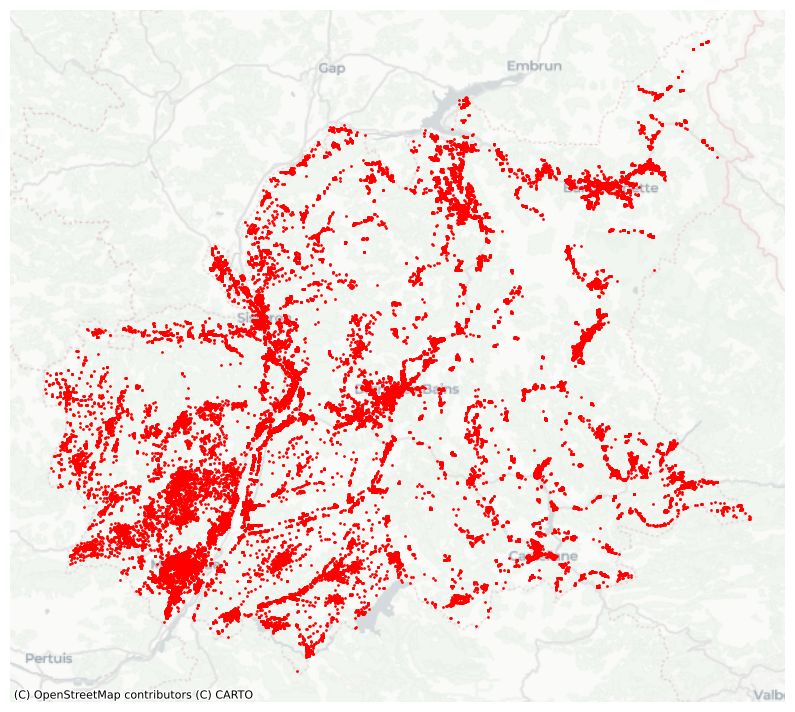

In [6]:
plot.plot_ban_data(df)

Cette carte est celles des adresses présentes dans la région Alpes de Haute Provence uniquement. Nous allons maintenant merger l'ensemble des bases afin d'avoir une carte pour la région PACA.

In [7]:
df_gen = extract.read_concatenated_ban_files(extract.BAN_ADRESS_FILES)

/home/onyxia/work/Groupe_KC_AHA_Python/main/ihf/../../modules/intern/ihf/ban/extract.py:40: DtypeWarning: Columns (16: nom_ld) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path, sep=";") # sep=";" the ihf ban files are semicolon separated


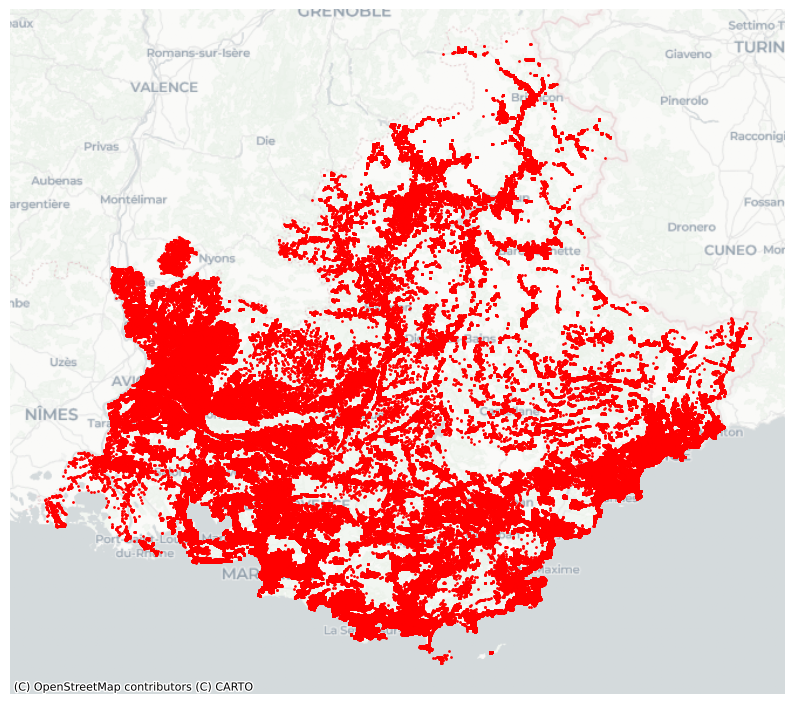

In [8]:
plot.plot_ban_data(df_gen)

## Forests PACA

Nous avons la base de données de l'occupation du sol dans la région du sud 2019.

In [9]:
gdf = extract_bdf.read_bd_forests_file()
gdf.head()

,id,niv1_19,lib1_19,niv2_19,lib2_19,niv3_19,lib3_19,area_m2,area_ha,exo_19,doute_19,fid,geometry
0,1,1,TERRITOIRES ARTIFICIALISES,12,"Zones industrielles ou Commerciales, infrastru...",122,Reseaux routier et ferroviaire et espaces asso...,2.570420e+08,25704.204736,BD Topo,Non,1.0,"POLYGON ((1038521.587 6293917.725, 1038514.322..."
1,2,5,SURFACES D EAU,52,Eaux maritimes,523,Mers et Oceans,2.664268e+09,266426.755790,BD TOPO,Non,2.0,"POLYGON ((849427.616 6249911.745, 849434.772 6..."
2,3,3,FORETS ET MILIEUX SEMI-NATURELS,31,Forets,311,Forets de feuillus,5.503453e+07,5503.453228,BD FORET,Non,3.0,"POLYGON ((880356 6298566, 880356 6298536, 8803..."
3,4,3,FORETS ET MILIEUX SEMI-NATURELS,31,Forets,311,Forets de feuillus,4.930583e+07,4930.582863,BD FORET,Non,4.0,"POLYGON ((978838.669 6240454.148, 978835.274 6..."
4,5,3,FORETS ET MILIEUX SEMI-NATURELS,33,"Espaces ouverts, sans ou avec peu de vegetation",333,Vegetation clairsemee,1.652205e+06,165.220459,Images Landsat 8,Non,5.0,"POLYGON ((989484.116 6289416.348, 989624.682 6..."


In [13]:
print(gdf.crs, len(gdf))

EPSG:2154 277512


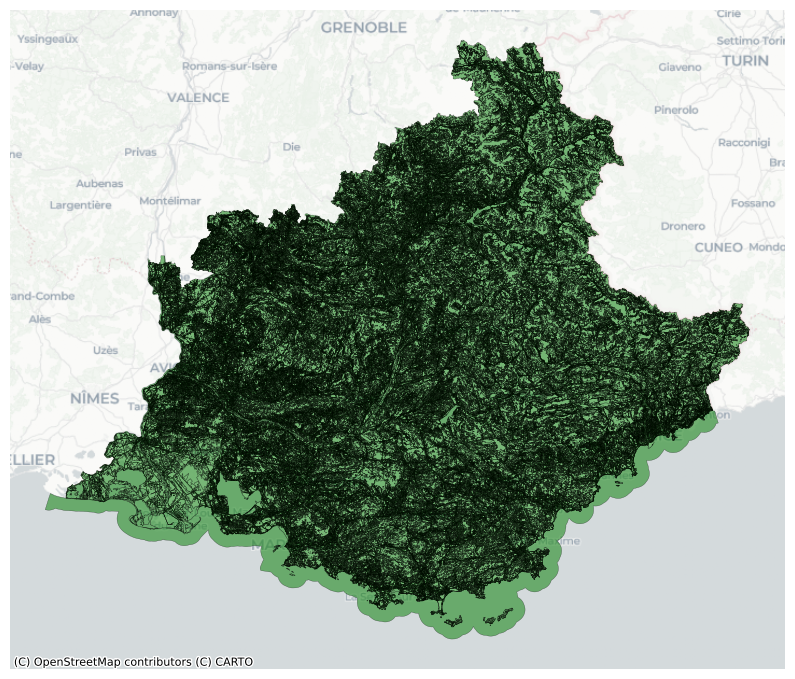

In [35]:
plot_bdf.plot_bd_forests_data(gdf)

Comme on peut le voir, la carte est plutôt confuse. Heureusement, nous ne nous intéressons qu'aux forêts, ce que nous faisons dans la suite

In [36]:
gdf_forest = gdf[gdf["exo_19"] == "BD FORET"]

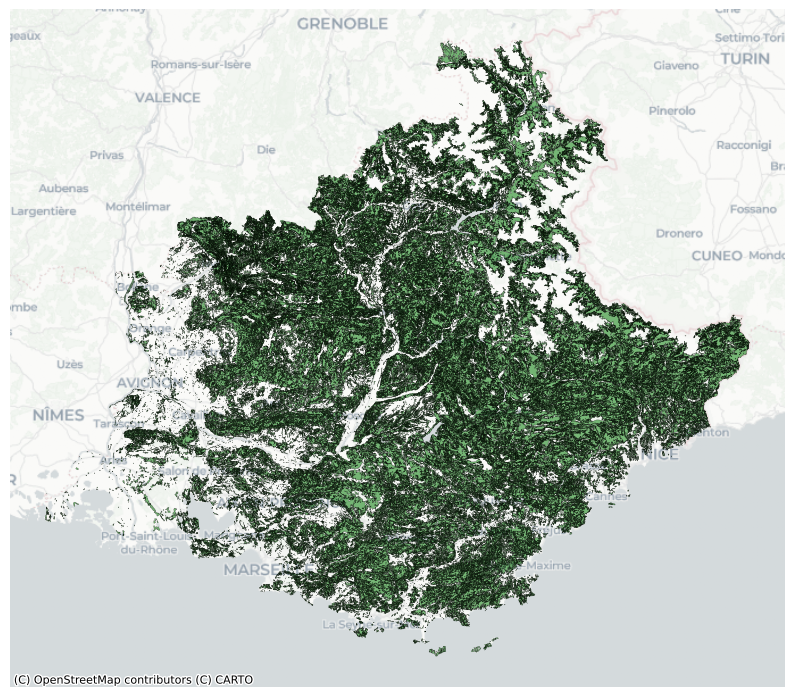

In [37]:
plot_bdf.plot_bd_forests_data(gdf_forest)